# Week 01 — Python packages and scientific code architecture

**Seismic Python & AI Engineering | Hands-on notebook**

You already know how to code. This week moves from stand-alone notebooks to an importable Python package with explicit contracts, reusable functions and tests.

**Estimated independent study:** 4–5 hours in this notebook, plus 2–3 hours on repository exercises and review.  
**Data:** entirely synthetic; no external API, proprietary dataset, or GPU required.  
**Prerequisite:** complete the root README setup and open Jupyter from the repository root.

### Learning outcomes
- Explain the purpose of `src/`, editable installs and `pyproject.toml`.
- Use modules, imports, type hints, docstrings and input contracts.
- Generate and inspect a reproducible synthetic seismic trace.
- Implement normalization as a testable reusable function.

### How to study
Read the explanations, execute the worked cells in order, complete the **Your turn** tasks, and implement the week's function in `src/seismic_toolkit/challenges.py`. Run the targeted exercise test to assess progress. The initial baseline tests should pass even before you complete the challenges.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

%pip install -e ..
from seismic_toolkit import __version__

print(f"Seismic toolkit version: {__version__}")
np.set_printoptions(precision=4, suppress=True)

Defaulting to user installation because normal site-packages is not writeable
Obtaining file:///C:/Users/guilhermetravassos/Downloads/projects_github/seismic-toolkit/seismic-python-ai-course
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for seismic-python-ai-course (pyproject.toml): started
  Building editable for seismic-python-ai-course (pyproject.toml): finished with status 'done'
  Created wheel for seismic-python-ai-course: filename=seismic_python_ai_course-0.1.0-0.editable-py3-none-any.whl size=7466 sha256=99f0e10cd9ba

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


## 1. The difference between a script and a package
A *script* can contain everything in one file and rely on execution order. A *package* exposes a deliberate API and makes dependencies explicit. In this repository, `src/seismic_toolkit/` contains importable production code; `notebooks/` contains experiments; `tests/` checks behavior.

Avoid putting business logic only in a notebook. Put a reusable operation in a `.py` function and call it from notebooks, tests and an app. This is the architectural foundation of the course.

In [4]:
from seismic_toolkit.synthetic import ricker, spike_reflectivity, synthetic_trace
from seismic_toolkit.attributes import trace_rms

wavelet = ricker(frequency=30.0, dt=0.001, duration=0.128)
reflectivity = spike_reflectivity(512, [120, 230, 350], [1.0, -0.6, 0.9])
trace = synthetic_trace(reflectivity, wavelet)
print(f"wavelet samples={len(wavelet)}; trace samples={len(trace)}; RMS={trace_rms(trace):.4f}")
assert len(trace) == 512

wavelet samples=129; trace samples=512; RMS=0.2056


## 2. A mathematical contract: the Ricker wavelet
For a frequency parameter \(f\) in hertz and time \(t\) in seconds,

\[
w(t) = (1-2(\pi f t)^2)\,\exp[-(\pi f t)^2].
\]

A discrete, symmetric wavelet needs an **odd** number of samples. Input validation ensures \(f>0\), \(\Delta t>0\), and \(f<1/(2\Delta t)\) (Nyquist). Convolution should preserve the length of reflectivity even when the wavelet is longer than the trace. A physically plausible numerical result is not enough; shape and units matter.

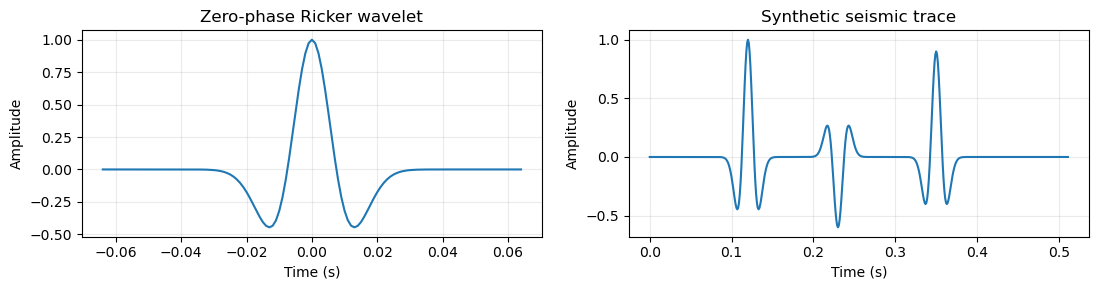

In [5]:
t_wavelet = (np.arange(len(wavelet)) - len(wavelet) // 2) * 0.001
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].plot(t_wavelet, wavelet)
axes[0].set(xlabel="Time (s)", ylabel="Amplitude", title="Zero-phase Ricker wavelet")
axes[1].plot(np.arange(len(trace)) * 0.001, trace)
axes[1].set(xlabel="Time (s)", ylabel="Amplitude", title="Synthetic seismic trace")
for ax in axes: ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 3. API contracts, validation and exceptions
A function contract describes **inputs**, **outputs**, **units**, **shape**, **edge cases**, and **errors**. Consider `ricker(30, 0.001, 0.128)`: the frequency is in Hz, `dt` and duration are in seconds, and the output is a 1D numeric vector.

> **Your turn A — edge cases:** Predict what should happen with a negative frequency, an empty reflectivity series, or an even-length wavelet. Run the cell and explain the exception types and messages. Then identify one missing corner case and write a test for it.

In [6]:
test_inputs = [(30, 0.001, 0.128), (-30, 0.001, 0.128), (700, 0.001, 0.128)]
for f, dt, duration in test_inputs:
    try:
        w = ricker(f, dt, duration)
        print(f"frequency={f}: OK, length={len(w)}")
    except ValueError as exc:
        print(f"frequency={f}: {type(exc).__name__}: {exc}")

frequency=30: OK, length=129
frequency=-30: ValueError: frequency must be a positive finite number
frequency=700: ValueError: frequency must be below the Nyquist frequency


**CONCLUSIONS**
1. Ricker requires positive frequencies;
2. Ricker also requires f < Nyquist frequency (  = 0.5/dt = 0.5/0.001 = 500Hz );

In [10]:
test_inputs = [(30, -0.001, 0.128), (30, 0.001, -0.128), (30, 0.001, 0), (30, 0.01, 0.001), (0, 0.01, 0.001), (30, 0, 0.001), (30, 0.01, 0)]
for f, dt, duration in test_inputs:
    try:
        w = ricker(f, dt, duration)
        print(f"frequency={f}: OK, length={len(w)}")
    except ValueError as exc:
        print(f"frequency={f}: {type(exc).__name__}: {exc}")

frequency=30: ValueError: dt must be a positive finite number
frequency=30: ValueError: duration must be a positive finite number
frequency=30: ValueError: duration must be a positive finite number
frequency=30: ValueError: duration must span at least two sample intervals
frequency=0: ValueError: frequency must be a positive finite number
frequency=30: ValueError: dt must be a positive finite number
frequency=30: ValueError: duration must be a positive finite number


## 4. Reading the project like a developer
Open `src/seismic_toolkit/synthetic.py`, `validation.py`, and `pyproject.toml` in VS Code. Trace the call chain from `synthetic_trace(...)` to `require_trace(...)`. What will happen if someone passes a string array? What error does the caller see?

**Key distinction:** a package can be installed *editable* (`pip install -e .`), so changes in `src/` are immediately available to your notebook kernel. If imports fail, check that Jupyter uses the same virtual environment as your terminal.

In [11]:
from pathlib import Path
from inspect import signature, getdoc

print("Public function signature:", signature(synthetic_trace))
print("First docstring line:", getdoc(synthetic_trace).splitlines()[0])
print("Current working directory:", Path.cwd())

Public function signature: (reflectivity: 'NDArray[np.float64]', wavelet: 'NDArray[np.float64]') -> 'NDArray[np.float64]'
First docstring line: Convolve reflectivity and an odd-length wavelet, preserving trace size.
Current working directory: C:\Users\guilhermetravassos\Downloads\projects_github\seismic-toolkit\seismic-python-ai-course\notebooks


The function require_trace(array, "array") checks if array is a numpy array (only numerical values), if it has dimension == 1 and if it carries only finite values. 

## 5. Independent implementation — Week 1 challenge
Implement `normalize_trace(trace)` in `src/seismic_toolkit/challenges.py`. It must:

- Accept a finite nonempty 1D numeric array.
- Divide amplitudes by the maximum absolute value.
- Return a **new** NumPy array; never modify the input.
- Return zeros for a zero-amplitude input instead of dividing by zero.
- Reject nonfinite or non-1D input with `ValueError`.

**Your turn B:** Write a function-level docstring with parameters, return type and zero-trace behavior before you implement it. Then add tests for negative-only traces, a zero trace and invalid input.

In [45]:
from seismic_toolkit.challenges import normalize_trace

#arr=np.array([1, 2, 3, 4, 5, 6])
#np.zeros_like(arr)

#Negative trace
normalize_trace(np.array([-1,-1, -1]))

#Zero trace
normalize_trace(np.array([0,0,0]))

#Inf trace
normalize_trace(np.array([np.inf,0,0]))

ValueError: Trace must contain only finite values

In [47]:
# Example contract without giving away the implementation
example = np.array([-4.0, 0.0, 2.0])
expected = np.array([-1.0, 0.0, 0.5])
print("Input:", example)
print("Expected normalized output:", expected)
# After implementing: from seismic_toolkit.challenges import normalize_trace
print("Normalized output:", normalize_trace(example))

Input: [-4.  0.  2.]
Expected normalized output: [-1.   0.   0.5]
Normalized output: [-1.   0.   0.5]


## 6. Applied problem: baseline/monitor amplitude scaling
A monitor trace may differ from baseline by a scalar acquisition gain. Create two traces, one equal to 2.5 times the other. Compare their RMS, then reason about when normalization would make sense and when it could destroy meaningful 4D amplitude information.

**Stretch challenge:** add a reusable `gain_ratio(reference, candidate)` helper, document your convention and test the zero-energy case. Do not put interpretation policy inside a numerical helper without documenting it.

In [48]:
monitor_gain = 2.5 * trace
print("RMS baseline:", round(trace_rms(trace), 4))
print("RMS monitor:", round(trace_rms(monitor_gain), 4))
print("Ratio:", round(trace_rms(monitor_gain) / trace_rms(trace), 4))
assert np.isclose(trace_rms(monitor_gain) / trace_rms(trace), 2.5)

RMS baseline: 0.2056
RMS monitor: 0.514
Ratio: 2.5


In [64]:
from numpy.typing import NDArray

def gain_ratio(reference: NDArray[np.float64], candidate: NDArray[np.float64]) -> float:
    """ Estimate a gain that balances the RMS amplitudes of candidate and reference. 
    This function returns a gain that is the inverse of the ratio RMS_candidate / RMS_reference 
    """

    try:
        a_ref  = np.asarray(reference, dtype=np.float64)
        a_cand = np.asarray(candidate, dtype=np.float64)
    except (TypeError, ValueError) as exc:
        raise ValueError("Trace must contain numeric values") from exc

    if ( (a_ref.ndim != 1 or a_ref.size == 0) or (a_cand.ndim != 1 or a_cand.size == 0)  ) :
        raise ValueError("Trace must be a nonempty, one-dimensional array")

    if not ( np.all(np.isfinite(a_ref)) and np.all(np.isfinite(a_cand))  ):
        raise ValueError("Trace must contain only finite values")
    
    rms_ref = trace_rms(a_ref)
    rms_cand = trace_rms(a_cand)

    if (rms_ref == 0 or rms_cand == 0):
        raise ValueError("Cannot estimate gain from zero-RMS traces")
    
    return float(rms_ref/rms_cand)    

OBS: a global gain consider a full trace RMS, thus it can mask local information.

---

## Weekly submission and self-review

1. Complete the independent exercise in `src/seismic_toolkit/challenges.py`.
2. Run: `python -m pytest -o addopts='' -m exercise -k week1 -q`.
3. Run baseline regression tests: `python -m pytest -q`.
4. Commit a focused change to a feature branch; document what changed and why.
5. Record one failure mode, one design decision, and one next-step question in your learning journal.

**Further work:** see [`../exercises/week01.md`](../exercises/week01.md) for a graded problem, extra practice and acceptance criteria. Compare with `solutions/reference_challenges.py` only **after** attempting your own solution.

**Important:** all datasets and algorithms are educational demonstrations, not validated reservoir-interpretation systems.